**WHAT THE CHARTS SHOW**

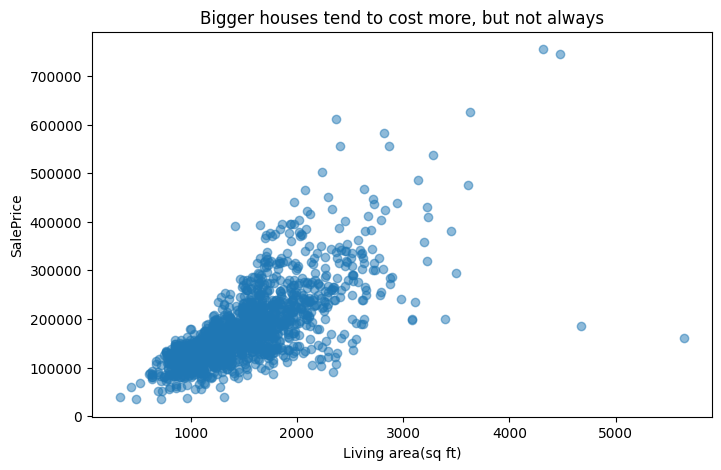

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("train.csv")

plt.figure(figsize = (8,5))
plt.scatter(df["GrLivArea"], df["SalePrice"], alpha = 0.5)
plt.title("Bigger houses tend to cost more, but not always")
plt.xlabel("Living area(sq ft)")
plt.ylabel("SalePrice")
plt.ticklabel_format(style = "plain", axis = "y")
plt.show()

*Bigger houses tend to cost more, but the two largest houses sold for only about 160,000 and 185,000*

**AVERAGE PRICE BY NEIGHBORHOOD**

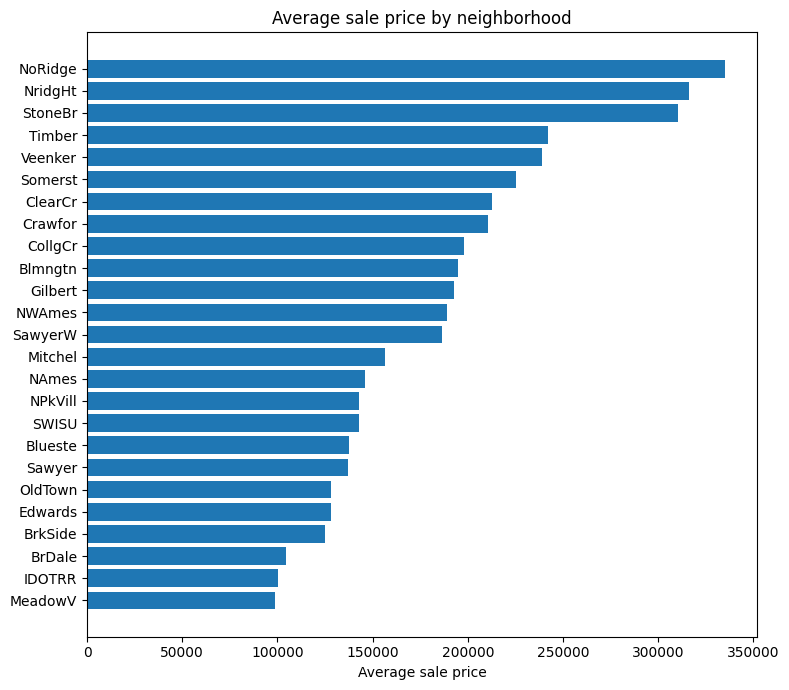

In [2]:
by_hood = df.groupby("Neighborhood")["SalePrice"].mean().sort_values()

plt.figure(figsize = (8,7))
plt.barh(by_hood.index, by_hood.values)
plt.title("Average sale price by neighborhood")
plt.xlabel("Average sale price")
plt.ticklabel_format(style = "plain", axis = "x")
plt.tight_layout()
plt.show()

*The most expensive neighborhood, NoRidge, averages about 3.4 times the cheapest, MeadowV.*

**MEDIAN PRICE BY OVERALL QUALITY**

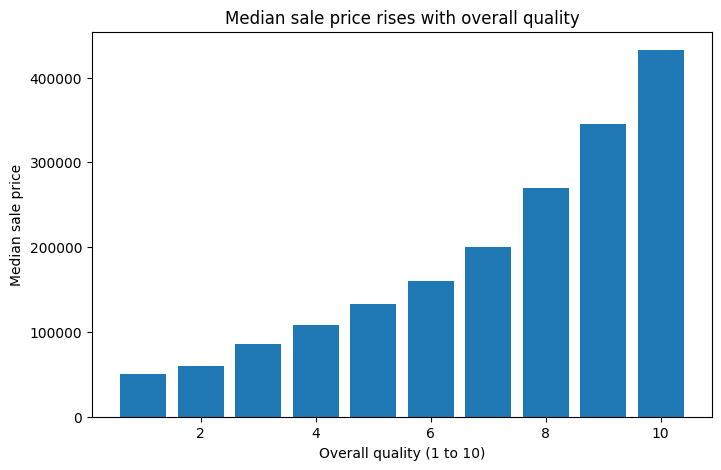

In [3]:
by_quality = df.groupby("OverallQual")["SalePrice"].median()

plt.figure(figsize=(8,5))
plt.bar(by_quality.index, by_quality.values)
plt.title("Median sale price rises with overall quality")
plt.xlabel("Overall quality (1 to 10)")
plt.ylabel("Median sale price")
plt.ticklabel_format(style = "plain", axis = "y")
plt.show()

*Median price climbs with every step up in overall quality*

**CHECKING THE CORRELATION BETWEEN SIZE AND QUALITY**

In [4]:
print(round(df["SalePrice"].corr(df["GrLivArea"]), 2))
print(round(df["SalePrice"].corr(df["OverallQual"]), 2))

0.71
0.79


In [5]:
df["HoodMean"] = df.groupby("Neighborhood")["SalePrice"].transform("mean")
print(round(df["SalePrice"].corr(df["HoodMean"]), 2))

0.74


*Price depends on quality, location, and size. Quality has the strongest link to price (correlation 0.79), followed by location (0.74) and size (0.71), but the factors are close together, and the two huge Edwards houses show that no single factor tells the whole story.*

**Note:** *location is measured using each neighborhood’s average price, which includes the house itself, so that number is slightly generous.*